# Sepsis: минимальный сценарий survpm

Журнал → DFG → сеть Петри → модель → генерация → восстановление → прогноз → все метрики библиотеки.
Подробные пояснения — в `petri_net_time_estimation_sepsis.ipynb`.

Нужны `pip install -e "survpm[metrics]"`, `log-distance-measures` (см. README) и graphviz (`brew install graphviz`).

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
warnings.filterwarnings("ignore")
import pm4py
from survpm import (CensoredStateNet, ProcessModel, ObjectStream, Simulator, Router, Forecaster,
                    discover, DirectlyFollowsBackend, Pm4pyBackend, evaluate, compare_networks, datasets)
from survpm.adapters import to_pm4py_log, draw_state_net
from survpm.metrics.crossval import CrossValidator, summarize

PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"
START, TERMINAL = "Registration", "Discharge"
RULES = dict(starts=[START], terminals=[TERMINAL])



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




## 1. Журнал и train/test

In [2]:
log = datasets.load_sepsis_log(PATH).prepare(RULES)
train, test = log.split("by_case", ratio=.8)
print("train/test объектов:", len(train.cases), len(test.cases))

train/test объектов: 840 210


## 2. DFG

Собственный backend (без PM4Py) и PM4Py DFG по train; рисунок — PM4Py с частотами.

рёбер: 15 | совпадение с PM4Py DFG: 1.0


,state,issue


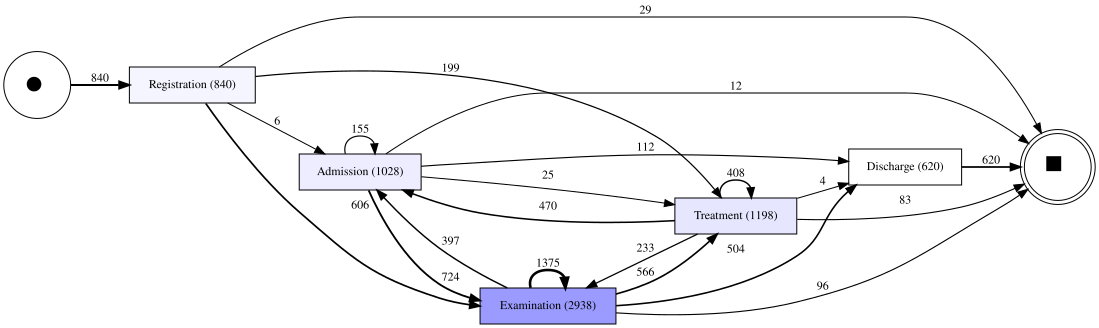

In [3]:
network = discover(train, DirectlyFollowsBackend(starts=[START], terminals=[TERMINAL]))
network_pm4py = Pm4pyBackend("dfg", starts=[START], terminals=[TERMINAL]).discover(train)
print("рёбер:", len(network.edges), "| совпадение с PM4Py DFG:", compare_networks(network, network_pm4py)["f1"])
display(network.validate())

from pm4py.visualization.dfg import visualizer as dfg_visualizer
dfg, starts, ends = pm4py.discover_dfg(to_pm4py_log(train.events))
dfg_visualizer.apply(dfg, parameters={"format": "svg", "start_activities": starts, "end_activities": ends})

## 3. Сеть Петри

Сеть состояний с местом `CENS` (цензура) и оценками на переходах — из `CensoredStateNet`
(та же exponential min-time модель); для сравнения — сеть Inductive Miner.

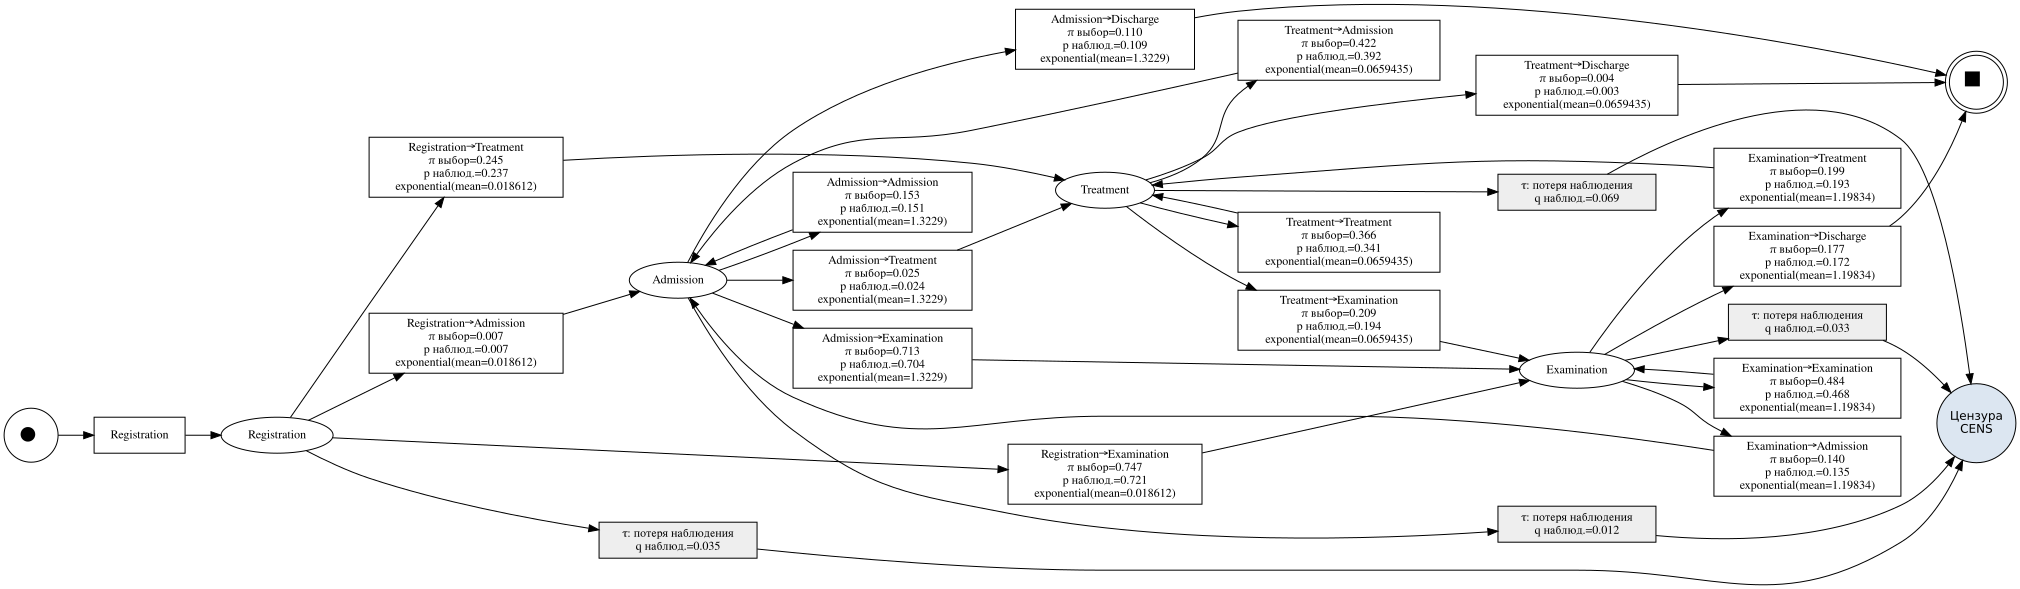

In [4]:
state_net = CensoredStateNet(START, TERMINAL).fit(train)
net, im, fm = state_net.to_pm4py(censoring=True)
draw_state_net(net, im, fm)

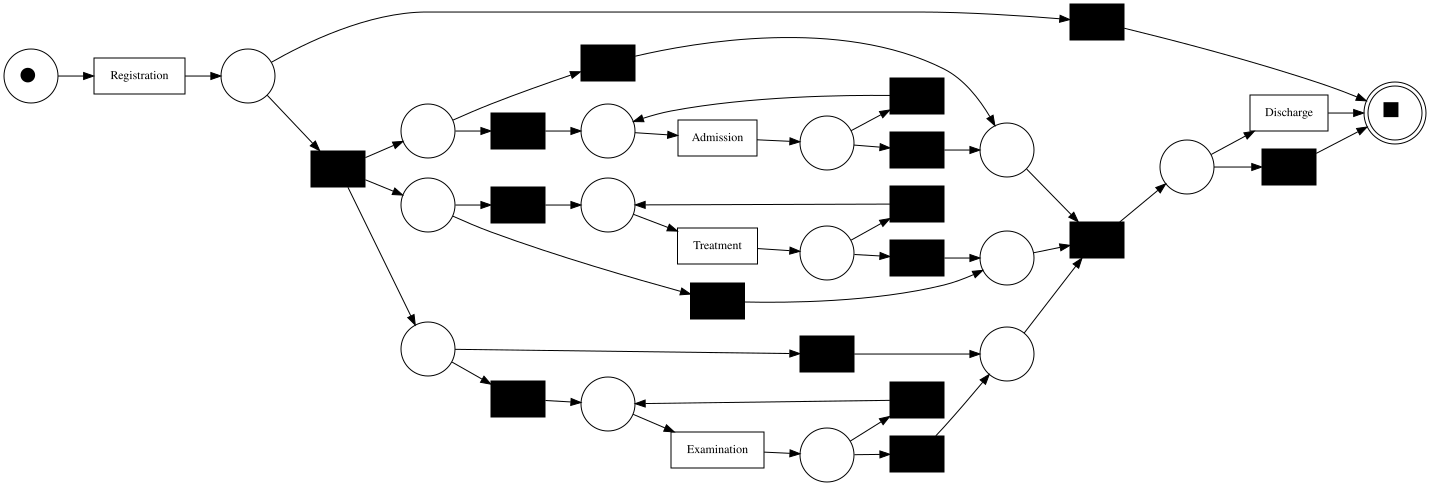

In [5]:
im_net, im_im, im_fm = pm4py.discover_petri_net_inductive(to_pm4py_log(train.events))
from pm4py.visualization.petri_net import visualizer as pn_visualizer
pn_visualizer.apply(im_net, im_im, im_fm, parameters={"format": "svg"})

## 4. Модель

In [6]:
model = ProcessModel(network).fit(train)
display(model.edges_table())

,src,dst,n_completed,n_visits,rate,p,mean_days
0,Registration,Examination,606,840,40.147529,0.747226,0.018612
1,Registration,Treatment,199,840,13.183760,0.245376,0.018612
2,Registration,Admission,6,840,0.397500,0.007398,0.018612
3,Examination,Treatment,566,2938,0.166193,0.199156,1.198341
4,Examination,Examination,1375,2938,0.403737,0.483814,1.198341
5,Examination,Discharge,504,2938,0.147988,0.177340,1.198341
6,Examination,Admission,397,2938,0.116570,0.139690,1.198341
7,Treatment,Admission,470,1198,6.392213,0.421525,0.065943
8,Treatment,Treatment,408,1198,5.548985,0.365919,0.065943
9,Treatment,Examination,233,1198,3.168906,0.208969,0.065943


## 5. Генерация

In [7]:
entries = train.events.groupby("case_id").timestamp.min()
stream = ObjectStream([dict(case_id=f"syn-{c}", state=START, t=t, X={}) for c, t in entries.items()])
synthetic = Simulator(model, seed=7).run(stream, horizon=60.)
display(synthetic.events.head(8))
display(synthetic.observation.reason.replace("", "Discharge").value_counts())

,case_id,activity,timestamp
0,syn-A,Registration,2014-10-22 09:15:41+00:00
1,syn-A,Treatment,2014-10-22 09:20:28.595355622+00:00
2,syn-A,Admission,2014-10-22 13:20:06.150830571+00:00
3,syn-A,Examination,2014-10-24 06:12:00.968034612+00:00
4,syn-A,Examination,2014-10-24 07:11:23.733554083+00:00
5,syn-A,Examination,2014-10-24 14:05:30.974845136+00:00
6,syn-A,Admission,2014-10-25 01:56:19.328535691+00:00
7,syn-A,Examination,2014-10-26 16:46:11.085532436+00:00


reason
Discharge    840
Name: count, dtype: int64

## 6. Восстановление: сеть и интенсивности по синтетике

In [8]:
recovered = discover(synthetic, DirectlyFollowsBackend(starts=[START], terminals=[TERMINAL]))
display(pd.Series({k: v for k, v in compare_networks(network, recovered).items() if k in ("precision", "recall", "f1")}))
refit = ProcessModel(network).fit(synthetic)
display(model.edges_table()[["src", "dst", "rate"]].merge(
    refit.edges_table()[["src", "dst", "rate"]], on=["src", "dst"], suffixes=("_model", "_recovered")))

precision    1.0
recall       1.0
f1           1.0
dtype: float64

,src,dst,rate_model,rate_recovered
0,Registration,Examination,40.147529,41.546280
1,Registration,Treatment,13.183760,12.979136
2,Registration,Admission,0.397500,0.260887
3,Examination,Treatment,0.166193,0.162160
4,Examination,Examination,0.403737,0.395266
5,Examination,Discharge,0.147988,0.146203
6,Examination,Admission,0.116570,0.121405
7,Treatment,Admission,6.392213,6.209019
8,Treatment,Treatment,5.548985,5.309445
9,Treatment,Examination,3.168906,3.353848


## 7. Прогноз test-объекта на момент второго события

In [9]:
case_id = test.events.case_id.iloc[0]
as_of = test.events.loc[test.events.case_id == case_id, "timestamp"].iloc[1]
forecaster = Forecaster(model, n_paths=1000, seed=1)
display(forecaster.survival(test, as_of, [1., 3., 7., 14., 30.], case_id=case_id))
display(forecaster.hazard(test, as_of, [1., 3., 7., 14., 30.], case_id=case_id))
print(forecaster.expected_time(test, as_of, horizon=30., case_id=case_id))
display(Router(model, seed=1).run(test, case_id, as_of, horizon=30.).events)  # один сгенерированный путь

,horizon,survival,cdf
0,1.0,0.849,0.151
1,3.0,0.655,0.345
2,7.0,0.418,0.582
3,14.0,0.170,0.830
4,30.0,0.023,0.977


,horizon,outcome,hazard
0,1.0,Discharge,0.151000
1,3.0,Discharge,0.114252
2,7.0,Discharge,0.090458
3,14.0,Discharge,0.084757
4,30.0,Discharge,0.054044


{'restricted_mean_time': 7.684665386803335, 'probability_unfinished': 0.023}


,case_id,activity,timestamp
0,UP,Examination,2014-05-16 08:56:00+00:00
1,UP,Treatment,2014-05-16 11:33:10.334883611+00:00
2,UP,Treatment,2014-05-16 12:02:31.624929065+00:00
3,UP,Admission,2014-05-16 13:47:05.529243945+00:00
4,UP,Admission,2014-05-17 18:05:03.722473021+00:00
5,UP,Examination,2014-05-20 12:00:36.735321661+00:00
6,UP,Discharge,2014-05-22 10:53:42.155404670+00:00


## 8. Метрики на test

* v2: `evaluate(model, test)` — NLL с цензурой;
* все метрики уровней 1–4 (`CensoredStateNet.evaluate(test, "all")`): process mining, стохастические,
  временные, правдоподобие;
* 5-fold CV по целым трассам с теми же метриками: naive против censor-aware.

In [10]:
display(evaluate(model, test, metrics=["nll"])["nll"])
holdout = state_net.evaluate(test, "all")
for level, table in holdout.items():
    print(level)
    display(table.set_index("model").T.rename_axis(None, axis=1))

,metric,value
0,nll_per_interval,1.004434
1,nll_per_trace,7.361064


replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 3002.52it/s]

replaying log with TBR, completed traces ::   0%|          | 0/11 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 11/11 [00:00<00:00, 5089.61it/s]

replaying log with TBR, completed traces ::   0%|          | 0/329 [00:00<?, ?it/s]

... (7 outputs left out)

level3


,train_log,model
temporal_deviation_share,0.128571,0.061905
cfld,NaN,0.299307
ngram_3,NaN,0.193824
cycle_time_emd,NaN,33.152381
absolute_event_emd,NaN,444.840536
edge_ks,NaN,0.412543
km_sup,NaN,0.194339
km_l1_days,NaN,1.395423
logrank_statistic,NaN,0.074948
logrank_p,NaN,0.784264


level4


,model
unseen_share,0.000000
nll_per_interval,1.004434
nll_per_trace,7.361064


In [11]:
cv = CrossValidator(START, TERMINAL, k=5).add_metrics("all").run(log)
for level, table in cv.items():
    print(level)
    display(summarize(table).T)

replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 4546.57it/s]

replaying log with TBR, completed traces ::   0%|          | 0/14 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 14/14 [00:00<00:00, 4912.18it/s]

replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 2116.03it/s]

... (97 outputs left out)

level3


model                          train_log       naive  censor_aware
temporal_deviation_share mean   0.140000    0.137143      0.137143
                         std    0.025332    0.028051      0.028051
cfld                     mean        NaN    0.292827      0.292827
                         std         NaN    0.004855      0.004855
ngram_3                  mean        NaN    0.208655      0.208655
                         std         NaN    0.017593      0.017593
cycle_time_emd           mean        NaN   27.863810     27.863810
                         std         NaN    1.387270      1.390483
absolute_event_emd       mean        NaN  247.687662    247.686375
                         std         NaN   86.407074     86.404555
edge_ks                  mean        NaN    0.404897      0.404884
                         std         NaN    0.010830      0.010829
km_sup                   mean        NaN    0.201434      0.201394
                         std         NaN    0.025232      0.025268
km_l1_days               mean        NaN    1.634147      1.634186
                         std         NaN    0.301300      0.301369
logrank_statistic        mean        NaN    1.046924      1.047254
                         std         NaN    0.714075      0.714340
logrank_p                mean        NaN    0.367755      0.367669
                         std         NaN    0.214289      0.214224
ibs                      mean        NaN    0.212121      0.212121
                         std         NaN    0.002880      0.002880

level4


model                     naive  censor_aware
unseen_share     mean  0.000000      0.000000
                 std   0.000000      0.000000
nll_per_interval mean  1.068034      1.068021
                 std   0.073786      0.073727
nll_per_trace    mean  7.666512      7.666431
                 std   0.491954      0.491740